In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## reliability-diagram

**Figure 2: Confidence histograms (top) and reliability diagrams (bottom) for a 5-layer LeNet (left) and a 110-layer ResNet (right) on CIFAR-100.** In the histograms, the dashed and dotted lines mark the average confidence and the accuracy; in the reliability diagrams, each gap bar spans from a bin's accuracy to its average confidence, and the dashed diagonal marks perfect calibration. The ResNet is more accurate (error 30.6% vs. 44.9%) but overconfident, with an average confidence of 0.884 against an accuracy of 0.705, whereas LeNet's average confidence (0.500) stays close to its accuracy (0.541).

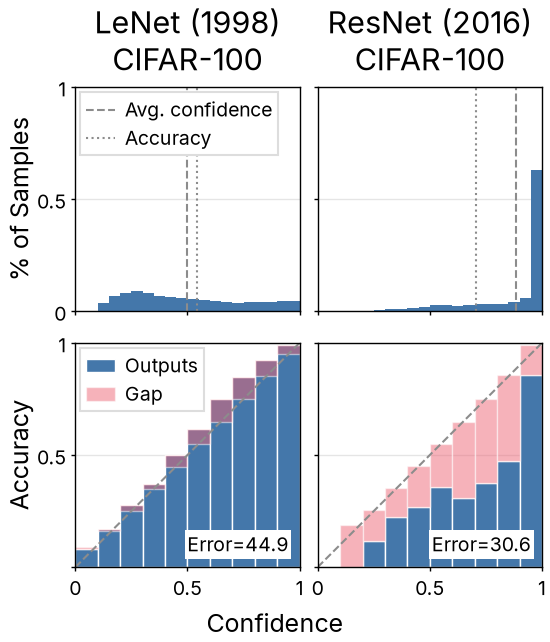

In [2]:
with open("../data/reliability-diagram.json") as f:
    data = json.load(f)
hist_edges = np.array(data["histogram_bin_edges"])
rel_edges = np.array(data["reliability_bin_edges"])

fig, axes = plt.subplots(2, 2, figsize=(2.75, 2.75), sharex="col", sharey="row")
for col, name in enumerate(["lenet", "resnet"]):
    model = data["models"][name]
    ax_hist, ax_rel = axes[0, col], axes[1, col]
    ax_hist.set_title(f"{model['label']}\nCIFAR-100")

    ax_hist.bar(hist_edges[:-1], model["fraction_of_samples_per_bin"], width=np.diff(hist_edges),
                align="edge", color=colors["series-1"], linewidth=0)
    ax_hist.axvline(model["avg_confidence_line"], linestyle="--", linewidth=paper.dashed_width,
                    color=colors["neutral"], label="Avg. confidence")
    ax_hist.axvline(model["accuracy_line"], linestyle=":", linewidth=paper.dashed_width,
                    color=colors["neutral"], label="Accuracy")
    ax_hist.grid(axis="x", visible=False)

    accuracy = np.array(model["accuracy_per_bin"])
    confidence = np.array(model["avg_confidence_per_bin"])
    ax_rel.bar(rel_edges[:-1], accuracy, width=np.diff(rel_edges), align="edge",
               color=colors["series-1"], edgecolor="white", linewidth=0.5, label="Outputs")
    ax_rel.bar(rel_edges[:-1], confidence - accuracy, bottom=accuracy, width=np.diff(rel_edges), align="edge",
               color=colors["series-2"], alpha=0.5, edgecolor="white", linewidth=0.5, label="Gap")
    ax_rel.axline((0, 0), (1, 1), linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"],
                  zorder=1)
    ax_rel.text(0.95, 0.05, f"Error={model['error_percent']}", transform=ax_rel.transAxes, ha="right", va="bottom",
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax_rel.grid(axis="x", visible=False)

for ax in axes.flat:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
ticks = [0, 0.5, 1]
for ax in axes.flat:
    ax.set_xticks(ticks)
axes[0, 0].set_yticks(ticks)
axes[1, 0].set_yticks(ticks, labels=["", "0.5", "1"])
axes[0, 0].set_ylabel("% of Samples")
axes[1, 0].set_ylabel("Accuracy")
fig.supxlabel("Confidence")
axes[0, 0].legend(loc="upper left")
axes[1, 0].legend(loc="upper left")

fit_height(fig, axes, aspect=1.0, min_width=1.0)
fig.savefig("../outputs/reliability-diagram.pdf")
fig.savefig("../outputs/reliability-diagram.png")
plt.show()